# Create shapefile of IGE's Elmer/Ice ISMIP6 domains

 - Author: Lucas Bastien.
 - Copyright (c) 2025-now, Institut des Géosciences de l'Environnement, (IGE, UMR 5001), Grenoble, France.
 - License: [BSD 3-clause "New" or "Revised" license](https://spdx.org/licenses/BSD-3-Clause.html).

 With this notebook we create a shapefile containing the perimeter of the Greenland and Antarctica domains used by IGE for their participation to the ISMIP6 exercice with the Elmer/Ice model.

## Dependencies

In [1]:
import subprocess
import pyproj
import netCDF4
import shapely
import shapefile
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cartopy

# Print system and package information
import watermark

%load_ext watermark
%watermark --machine --python --iversions

Python implementation: CPython
Python version       : 3.13.2
IPython version      : 9.0.2

Compiler    : Clang 18.1.8 
OS          : Darwin
Release     : 25.0.0
Machine     : arm64
Processor   : arm
CPU cores   : 8
Architecture: 64bit

matplotlib: 3.10.1
pyproj    : 3.7.1
netCDF4   : 1.7.2
shapefile : 2.3.1
watermark : 2.5.0
cartopy   : 0.24.0
shapely   : 2.0.7



# Get the ice sheet masks from Elmer/Ice outputs

In [2]:
def transform_from_crs(epsg, reverse=False):
    """Return the pyproj transform function corresponding to given CRS.

    Parameters
    ----------
    epsg : int
        The EPSG code of the transformation.
    reverse : bool
        The direction of the transformation:
         - False: from (lon,lat) to (x,y).
         - True: from (x,y) to (lon,lat).

    Returns
    -------
    pyproj.Transformer.transform
        A function to convert (lon,lat) to (x,y), or the other way around if
        reverse is True.

    Notes
    -----
    This function was adapted from the geomodeloutputs Python package (same
    copyright and license as this notebook). See:
    https://gricad-gitlab.univ-grenoble-alpes.fr/bastiluc/geomodeloutputs or
    https://github.com/lucas-ige/geomodeloutputs

    """
    crs = pyproj.CRS.from_epsg(epsg)
    fr = crs.geodetic_crs
    to = crs
    if reverse:
        fr, to = to, fr
    return pyproj.Transformer.from_crs(fr, to, always_xy=True).transform

In [3]:
def get_icesheet_mask(icesheet):
    """Return perimeter of ice sheet.

    Parameters
    ----------
    icesheet: str
        Name of the ice sheet.

    Returns
    -------
    shapely.Polygon
        The polygon representing the perimeter of the ice sheet (in longitude,
        latitude) coordinates.

    Notes
    -----
    We implement this function using brute-force. It is quite straight-forward
    but it may take some time to execute.

    """

    # Open one of IGE's Elmer/Ice ISMIP6 output files
    ds = netCDF4.Dataset("%s.nc" % icesheet)
    varname_lon = "%s_node_x" % icesheet
    varname_lat = "%s_node_y" % icesheet

    # Do some quality control on the file
    if ds[varname_lon].standard_name != "longitude":
        raise ValueError("Bad standard name for %s." % varname_lon)
    if ds[varname_lon].units != "degrees_east":
        raise ValueError("Bad units name for %s." % varname_lon)
    if ds[varname_lat].standard_name != "latitude":
        raise ValueError("Bad standard name for %s." % varname_lat)
    if ds[varname_lat].units != "degrees_north":
        raise ValueError("Bad units name for %s." % varname_lat)

    # We work in (x,y) space otherwise the +/-180 meridian creates problems
    epsg = dict(antarctica=3031, greenland=3413)[icesheet]
    x, y = transform_from_crs(epsg)(ds[varname_lon], ds[varname_lat])

    # Get the cell-to-node mapping
    varname_nodes = "%s_face_nodes" % icesheet
    nodes = ds[varname_nodes][:]
    if ds[varname_nodes].start_index > 0:
        nodes -= ds[varname_nodes].start_index
    elif ds[varname_nodes].start_index != 0:
        raise ValueError("Negative start_index for %s." % varname_nodes)

    # Create a list of polygons representing the cells
    cells = []
    for i in range(nodes.shape[0]):
        xi = [x[j] for j in nodes[i, :]]
        yi = [y[j] for j in nodes[i, :]]
        cells.append(shapely.Polygon(zip(xi, yi)))

    # Get and return the outter contour of this group of cells
    perimeter = list(shapely.union_all(cells).exterior.coords)
    x, y = zip(*perimeter)
    lon, lat = transform_from_crs(epsg, reverse=True)(x, y)
    return list(zip(lon, lat))

In [4]:
antarctica = get_icesheet_mask("antarctica")

In [5]:
greenland = get_icesheet_mask("greenland")

# Plot the perimeters to check visually that it looks good

In [6]:
# Graphical parameters

gprm_coast = dict(lw=0.5, color="0.8", zorder=-2)
gprm_domain = dict(ec="r", fc="none", lw=0.1)

In [7]:
# Projection parameters

crs_lonlat = cartopy.crs.Geodetic()
crs_greenland = cartopy.crs.NorthPolarStereo(
    central_longitude=-45,
    true_scale_latitude=70,
)
crs_antarctica = cartopy.crs.SouthPolarStereo(
    central_longitude=0,
    true_scale_latitude=-71,
)


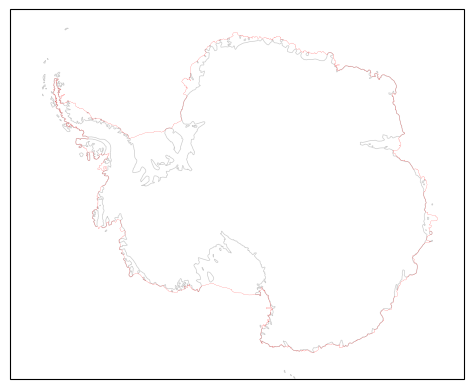

In [8]:
# Antarctica

fig = plt.figure()
ax = fig.add_subplot(projection=crs_antarctica)
ax.coastlines(**gprm_coast)
domain = patches.Polygon(antarctica, transform=crs_lonlat, **gprm_domain)
ax.set_xlim(-3100000, 3100000)
ax.set_ylim(-2500000, 2550000)
patch = ax.add_patch(domain)

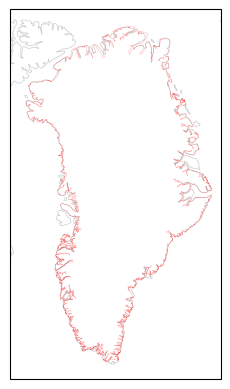

In [9]:
# Greenland

fig = plt.figure()
ax = fig.add_subplot(projection=crs_greenland)
ax.coastlines(**gprm_coast)
domain = patches.Polygon(greenland, transform=crs_lonlat, **gprm_domain)
ax.set_xlim(-750000, 920000)
ax.set_ylim(-3460000, -533000)
patch = ax.add_patch(domain)

# Save the perimeters of these two domains in a shapefile

The goal here is to create a shapefile that follows the metadata conventions used for reference regions in the [Multi-MIP Climate Change ATLAS](https://github.com/SantanderMetGroup/ATLAS) (commit a1687c6db5590eb9b618fd4e1ebba4b842084031), more specifically in the file `reference-regions/IPCC-WGI-reference-regions-v4_shapefile.zip` (here is [a more robust link to this file for the specific commit mentionned here](https://archive.softwareheritage.org/swh:1:cnt:87a19e01d020499f2249a96c05602e9ffa4b88b4;origin=https://github.com/SantanderMetGroup/ATLAS;visit=swh:1:snp:831c9c668030b5db7626bfd20e4cb13488a4d59c;anchor=swh:1:rev:a1687c6db5590eb9b618fd4e1ebba4b842084031;path=/reference-regions/IPCC-WGI-reference-regions-v4_shapefile.zip)).

This shapefile is of type 5 (POLYGON) in pyshp jargon.

This shapefile contains the following fields:

 - 'Continent', 'C', 80, 0,
 - 'Type', 'C', 80, 0,
 - 'Name', 'C', 80, 0,
 - 'Acronym', 'C', 80, 0

Here are the records in this shapefile (the coordinates of the shapes are given in this order: longitude, latitude):

```
Record #0: ['POLAR', 'Land', 'Greenland/Iceland', 'GIC']
Record #1: ['NORTH-AMERICA', 'Land', 'N.W.North-America', 'NWN']
Record #2: ['NORTH-AMERICA', 'Land', 'N.E.North-America', 'NEN']
Record #3: ['NORTH-AMERICA', 'Land', 'W.North-America', 'WNA']
Record #4: ['NORTH-AMERICA', 'Land', 'C.North-America', 'CNA']
Record #5: ['NORTH-AMERICA', 'Land', 'E.North-America', 'ENA']
Record #6: ['CENTRAL-AMERICA', 'Land', 'N.Central-America', 'NCA']
Record #7: ['CENTRAL-AMERICA', 'Land', 'S.Central-America', 'SCA']
Record #8: ['CENTRAL-AMERICA', 'Land-Ocean', 'Caribbean', 'CAR']
Record #9: ['SOUTH-AMERICA', 'Land', 'N.W.South-America', 'NWS']
Record #10: ['SOUTH-AMERICA', 'Land', 'N.South-America', 'NSA']
Record #11: ['SOUTH-AMERICA', 'Land', 'N.E.South-America', 'NES']
Record #12: ['SOUTH-AMERICA', 'Land', 'South-American-Monsoon', 'SAM']
Record #13: ['SOUTH-AMERICA', 'Land', 'S.W.South-America', 'SWS']
Record #14: ['SOUTH-AMERICA', 'Land', 'S.E.South-America', 'SES']
Record #15: ['SOUTH-AMERICA', 'Land', 'S.South-America', 'SSA']
Record #16: ['EUROPE', 'Land', 'N.Europe', 'NEU']
Record #17: ['EUROPE', 'Land', 'West&Central-Europe', 'WCE']
Record #18: ['EUROPE', 'Land', 'E.Europe', 'EEU']
Record #19: ['EUROPE-AFRICA', 'Land-Ocean', 'Mediterranean', 'MED']
Record #20: ['AFRICA', 'Land', 'Sahara', 'SAH']
Record #21: ['AFRICA', 'Land', 'Western-Africa', 'WAF']
Record #22: ['AFRICA', 'Land', 'Central-Africa', 'CAF']
Record #23: ['AFRICA', 'Land', 'N.Eastern-Africa', 'NEAF']
Record #24: ['AFRICA', 'Land', 'S.Eastern-Africa', 'SEAF']
Record #25: ['AFRICA', 'Land', 'W.Southern-Africa', 'WSAF']
Record #26: ['AFRICA', 'Land', 'E.Southern-Africa', 'ESAF']
Record #27: ['AFRICA', 'Land', 'Madagascar', 'MDG']
Record #28: ['ASIA', 'Land', 'Russian-Arctic', 'RAR']
Record #29: ['ASIA', 'Land', 'W.Siberia', 'WSB']
Record #30: ['ASIA', 'Land', 'E.Siberia', 'ESB']
Record #31: ['ASIA', 'Land', 'Russian-Far-East', 'RFE']
Record #32: ['ASIA', 'Land', 'W.C.Asia', 'WCA']
Record #33: ['ASIA', 'Land', 'E.C.Asia', 'ECA']
Record #34: ['ASIA', 'Land', 'Tibetan-Plateau', 'TIB']
Record #35: ['ASIA', 'Land', 'E.Asia', 'EAS']
Record #36: ['ASIA', 'Land', 'Arabian-Peninsula', 'ARP']
Record #37: ['ASIA', 'Land', 'S.Asia', 'SAS']
Record #38: ['ASIA', 'Land-Ocean', 'S.E.Asia', 'SEA']
Record #39: ['OCEANIA', 'Land', 'N.Australia', 'NAU']
Record #40: ['OCEANIA', 'Land', 'C.Australia', 'CAU']
Record #41: ['OCEANIA', 'Land', 'E.Australia', 'EAU']
Record #42: ['OCEANIA', 'Land', 'S.Australia', 'SAU']
Record #43: ['OCEANIA', 'Land', 'New-Zealand', 'NZ']
Record #44: ['POLAR', 'Land', 'E.Antarctica', 'EAN']
Record #45: ['POLAR', 'Land', 'W.Antarctica', 'WAN']
Record #46: ['ARCTIC', 'Ocean', 'Arctic-Ocean', 'ARO']
Record #47: ['PACIFIC', 'Ocean', 'N.Pacific-Ocean', 'NPO']
Record #48: ['PACIFIC', 'Ocean', 'Equatorial.Pacific-Ocean', 'EPO']
Record #49: ['PACIFIC', 'Ocean', 'S.Pacific-Ocean', 'SPO']
Record #50: ['ATLANTIC', 'Ocean', 'N.Atlantic-Ocean', 'NAO']
Record #51: ['ATLANTIC', 'Ocean', 'Equatorial.Atlantic-Ocean', 'EAO']
Record #52: ['ATLANTIC', 'Ocean', 'S.Atlantic-Ocean', 'SAO']
Record #53: ['INDIAN', 'Ocean', 'Arabian-Sea', 'ARS']
Record #54: ['INDIAN', 'Ocean', 'Bay-of-Bengal', 'BOB']
Record #55: ['INDIAN', 'Ocean', 'Equatorial.Indian-Ocean', 'EIO']
Record #56: ['INDIAN', 'Ocean', 'S.Indian-Ocean', 'SIO']
Record #57: ['SOUTHERN', 'Ocean', 'Southern-Ocean', 'SOO']
```


In [10]:
# We write our shapefile following these conventions

filename = "ismip6-masks-IGE-ElmerIce"
out = subprocess.run(
    ["rm"]
    + ["%s.%s" % (filename, ext) for ext in ("dbf", "shp", "shx", "zip")]
)

with shapefile.Writer(filename) as writer:
    writer.shapeType = shapefile.POLYGON
    writer.field("Continent", "C", 80, 0)
    writer.field("Type", "C", 80, 0)
    writer.field("Name", "C", 80, 0)
    writer.field("Acronym", "C", 80, 0)

    # Antarctica
    writer.poly([antarctica])
    writer.record(
        Continent="POLAR",
        Type="Land",
        Name="IGE's ISMIP6 Elmer/Ice Antarctica domain",
        Acronym="AIS",
    )

    # Greenland
    writer.poly([greenland])
    writer.record(
        Continent="POLAR",
        Type="Land",
        Name="IGE's ISMIP6 Elmer/Ice Greenland domain",
        Acronym="GIS",
    )

out = subprocess.run(
    ["zip", filename]
    + ["%s.%s" % (filename, ext) for ext in ("dbf", "shp", "shx")]
)

  adding: ismip6-masks-IGE-ElmerIce.dbf (deflated 83%)
  adding: ismip6-masks-IGE-ElmerIce.shp (deflated 55%)
  adding: ismip6-masks-IGE-ElmerIce.shx (deflated 45%)
